In [10]:
import os, zipfile, shutil, random
from google.colab import files

uploaded = files.upload()
zip_name = list(uploaded.keys())[0]

raw = "/content/raw_catsdogs"
os.makedirs(raw, exist_ok=True)
with zipfile.ZipFile(zip_name) as z:
    z.extractall(raw)

exts = (".jpg", ".jpeg", ".png", ".bmp")
cats, dogs = [], []
for root, _, fnames in os.walk(raw):
    for f in fnames:
        if f.lower().endswith(exts):
            path = os.path.join(root, f)
            fname = f.lower()
            parent = os.path.basename(root).lower()
            if "cat" in fname and "dog" not in fname:
                cats.append(path)
            elif "dog" in fname and "cat" not in fname:
                dogs.append(path)
            elif parent in ("cat", "cats"):
                cats.append(path)
            elif parent in ("dog", "dogs"):
                dogs.append(path)

print("Cats:", len(cats), "| Dogs:", len(dogs))

random.seed(42)
base = "/content/catsdogs"
shutil.rmtree(base, ignore_errors=True)
for label, items in [("cats", cats), ("dogs", dogs)]:
    random.shuffle(items)
    cut = int(len(items) * 0.8)
    for split, subset in [("train", items[:cut]), ("val", items[cut:])]:
        out = os.path.join(base, split, label)
        os.makedirs(out, exist_ok=True)
        for p in subset:
            shutil.copy(p, os.path.join(out, os.path.basename(p)))

train_dir = os.path.join(base, "train")
val_dir = os.path.join(base, "val")
print(os.listdir(train_dir), os.listdir(val_dir))

Saving cats_dogs_light.zip to cats_dogs_light (1).zip
Cats: 655 | Dogs: 745
['dogs', 'cats'] ['dogs', 'cats']


In [11]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2, VGG16
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D, Conv2D, MaxPooling2D, Flatten
from tensorflow.keras.models import Sequential, Model
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

IMG_SIZE=(224,224)
BATCH_SIZE=32
EPOCHS=5

In [12]:
train_gen=ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True)

val_gen=ImageDataGenerator(rescale=1./255)

train_ds=train_gen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary")

val_ds=val_gen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False)

Found 1120 images belonging to 2 classes.
Found 280 images belonging to 2 classes.


In [13]:
cnn=Sequential([
    tf.keras.Input(shape=(224,224,3)),
    Conv2D(32,3,activation="relu"),
    MaxPooling2D(),
    Conv2D(64,3,activation="relu"),
    MaxPooling2D(),
    Conv2D(128,3,activation="relu"),
    MaxPooling2D(),
    Flatten(),
    Dense(128,activation="relu"),
    Dropout(0.5),
    Dense(1,activation="sigmoid")
])

cnn.compile(optimizer="adam",
            loss="binary_crossentropy",
            metrics=["accuracy"])

cnn_history=cnn.fit(train_ds,
                    validation_data=val_ds,
                    epochs=EPOCHS)

Epoch 1/5
35/35 ━━━━━━━━━━━━━━━━━━━━ 21s 505ms/step - accuracy: 0.4821 - loss: 0.8107 - val_accuracy: 0.4679 - val_loss: 0.6956
Epoch 2/5
35/35 ━━━━━━━━━━━━━━━━━━━━ 18s 500ms/step - accuracy: 0.5161 - loss: 0.6938 - val_accuracy: 0.5321 - val_loss: 0.6896
Epoch 3/5
35/35 ━━━━━━━━━━━━━━━━━━━━ 17s 488ms/step - accuracy: 0.5330 - loss: 0.6924 - val_accuracy: 0.5321 - val_loss: 0.6899
Epoch 4/5
35/35 ━━━━━━━━━━━━━━━━━━━━ 19s 535ms/step - accuracy: 0.5304 - loss: 0.6902 - val_accuracy: 0.5321 - val_loss: 0.6877
Epoch 5/5
35/35 ━━━━━━━━━━━━━━━━━━━━ 17s 481ms/step - accuracy: 0.5455 - loss: 0.6863 - val_accuracy: 0.5393 - val_loss: 0.6752


In [14]:
base=MobileNetV2(weights="imagenet",
                  include_top=False,
                  input_shape=(224,224,3))

base.trainable=False

x=GlobalAveragePooling2D()(base.output)
x=Dense(128,activation="relu")(x)
x=Dropout(0.5)(x)
output=Dense(1,activation="sigmoid")(x)

mobilenet=Model(base.input,output)

mobilenet.compile(optimizer="adam",
                  loss="binary_crossentropy",
                  metrics=["accuracy"])

mobilenet.fit(train_ds,
              validation_data=val_ds,
              epochs=EPOCHS)

# Fine-tuning
base.trainable=True
for layer in base.layers[:-30]:
    layer.trainable=False

mobilenet.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"])

mobilenet.fit(train_ds,
              validation_data=val_ds,
              epochs=2)

Epoch 1/5
35/35 ━━━━━━━━━━━━━━━━━━━━ 31s 647ms/step - accuracy: 0.9152 - loss: 0.1952 - val_accuracy: 0.9821 - val_loss: 0.0518
Epoch 2/5
35/35 ━━━━━━━━━━━━━━━━━━━━ 19s 527ms/step - accuracy: 0.9714 - loss: 0.0823 - val_accuracy: 0.9714 - val_loss: 0.0665
Epoch 3/5
35/35 ━━━━━━━━━━━━━━━━━━━━ 17s 489ms/step - accuracy: 0.9741 - loss: 0.0754 - val_accuracy: 0.9786 - val_loss: 0.0519
Epoch 4/5
35/35 ━━━━━━━━━━━━━━━━━━━━ 17s 489ms/step - accuracy: 0.9812 - loss: 0.0563 - val_accuracy: 0.9786 - val_loss: 0.0530
Epoch 5/5
35/35 ━━━━━━━━━━━━━━━━━━━━ 19s 526ms/step - accuracy: 0.9812 - loss: 0.0497 - val_accuracy: 0.9821 - val_loss: 0.0292
Epoch 1/2
35/35 ━━━━━━━━━━━━━━━━━━━━ 39s 689ms/step - accuracy: 0.8679 - loss: 0.3607 - val_accuracy: 0.9857 - val_loss: 0.0319
Epoch 2/2
35/35 ━━━━━━━━━━━━━━━━━━━━ 17s 477ms/step - accuracy: 0.9241 - loss: 0.1707 - val_accuracy: 0.9857 - val_loss: 0.0350


In [15]:
base2=VGG16(weights="imagenet",
             include_top=False,
             input_shape=(224,224,3))

base2.trainable=False

y = GlobalAveragePooling2D()(base2.output)
y=Dense(128,activation="relu")(y)
y=Dropout(0.5)(y)
output2=Dense(1,activation="sigmoid")(y)

vgg=Model(base2.input,output2)

vgg.compile(optimizer="adam",
            loss="binary_crossentropy",
            metrics=["accuracy"])

vgg.fit(train_ds,
        validation_data=val_ds,
        epochs=EPOCHS)

Epoch 1/5
35/35 ━━━━━━━━━━━━━━━━━━━━ 24s 584ms/step - accuracy: 0.5982 - loss: 0.6651 - val_accuracy: 0.8429 - val_loss: 0.5223
Epoch 2/5
35/35 ━━━━━━━━━━━━━━━━━━━━ 18s 524ms/step - accuracy: 0.7357 - loss: 0.5425 - val_accuracy: 0.8571 - val_loss: 0.4367
Epoch 3/5
35/35 ━━━━━━━━━━━━━━━━━━━━ 20s 548ms/step - accuracy: 0.7964 - loss: 0.4663 - val_accuracy: 0.8750 - val_loss: 0.3761
Epoch 4/5
35/35 ━━━━━━━━━━━━━━━━━━━━ 19s 530ms/step - accuracy: 0.8170 - loss: 0.4185 - val_accuracy: 0.8821 - val_loss: 0.3405
Epoch 5/5
35/35 ━━━━━━━━━━━━━━━━━━━━ 20s 566ms/step - accuracy: 0.8321 - loss: 0.3932 - val_accuracy: 0.8786 - val_loss: 0.3227


In [16]:
for name,model in [("CNN",cnn),
                   ("MobileNetV2",mobilenet),
                   ("VGG16",vgg)]:
    loss,acc=model.evaluate(val_ds,verbose=0)
    print(f"{name}: Accuracy = {acc:.4f}")

CNN: Accuracy = 0.5393
MobileNetV2: Accuracy = 0.9857
VGG16: Accuracy = 0.8786


In [17]:
val_ds.reset()
p1=cnn.predict(val_ds,verbose=0)

val_ds.reset()
p2=mobilenet.predict(val_ds,verbose=0)

val_ds.reset()
p3=vgg.predict(val_ds,verbose=0)

ensemble=((p1+p2+p3)/3>0.5).astype(int).flatten()

true=val_ds.classes

print("Ensemble Accuracy:",
      accuracy_score(true,ensemble))

print(classification_report(
    true,
    ensemble,
    target_names=["Cat","Dog"]))

Ensemble Accuracy: 0.975
              precision    recall  f1-score   support

         Cat       1.00      0.95      0.97       131
         Dog       0.96      1.00      0.98       149

    accuracy                           0.97       280
   macro avg       0.98      0.97      0.97       280
weighted avg       0.98      0.97      0.97       280



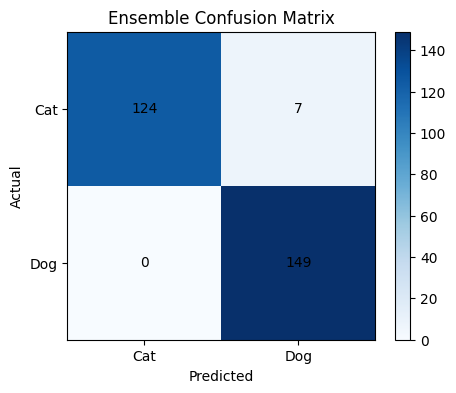

In [18]:
cm=confusion_matrix(true,ensemble)

plt.figure(figsize=(5,4))
plt.imshow(cm,cmap="Blues")
plt.colorbar()
plt.xticks([0,1],["Cat","Dog"])
plt.yticks([0,1],["Cat","Dog"])

for i in range(2):
    for j in range(2):
        plt.text(j,i,str(cm[i,j]),
                 ha="center",
                 va="center")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Ensemble Confusion Matrix")
plt.show()

In [19]:
from sklearn.metrics import accuracy_score

val_ds.reset()
cnn_pred = (cnn.predict(val_ds, verbose=0) > 0.5).astype(int).flatten()

val_ds.reset()
mobile_pred = (mobilenet.predict(val_ds, verbose=0) > 0.5).astype(int).flatten()

val_ds.reset()
vgg_pred = (vgg.predict(val_ds, verbose=0) > 0.5).astype(int).flatten()

print("CNN:", accuracy_score(true, cnn_pred))
print("MobileNetV2:", accuracy_score(true, mobile_pred))
print("VGG16:", accuracy_score(true, vgg_pred))
print("Ensemble:", accuracy_score(true, ensemble))

CNN: 0.5392857142857143
MobileNetV2: 0.9857142857142858
VGG16: 0.8785714285714286
Ensemble: 0.975


In [20]:
import numpy as np

cnn_pred = (p1 > 0.5).astype(int).flatten()
mobile_pred = (p2 > 0.5).astype(int).flatten()
vgg_pred = (p3 > 0.5).astype(int).flatten()

print("CNN mistakes:", np.sum(cnn_pred != true))
print("MobileNet mistakes:", np.sum(mobile_pred != true))
print("VGG mistakes:", np.sum(vgg_pred != true))
print("Ensemble mistakes:", np.sum(ensemble != true))

CNN mistakes: 129
MobileNet mistakes: 4
VGG mistakes: 34
Ensemble mistakes: 7


In [21]:
mobile_wrong = np.where(mobile_pred != true)[0]
print(mobile_wrong)

[  8  45 115 120]


In [22]:
for idx in mobile_wrong:
    print(f"Image {idx}")
    print("True Label:", true[idx])
    print("CNN:", cnn_pred[idx])
    print("MobileNet:", mobile_pred[idx])
    print("VGG:", vgg_pred[idx])
    print("Ensemble:", ensemble[idx])
    print("-" * 30)

Image 8
True Label: 0
CNN: 1
MobileNet: 1
VGG: 1
Ensemble: 1
------------------------------
Image 45
True Label: 0
CNN: 1
MobileNet: 1
VGG: 1
Ensemble: 1
------------------------------
Image 115
True Label: 0
CNN: 1
MobileNet: 1
VGG: 0
Ensemble: 1
------------------------------
Image 120
True Label: 0
CNN: 0
MobileNet: 1
VGG: 1
Ensemble: 1
------------------------------


In [23]:
print("Image 31")

print("CNN Probability       :", p1[31][0])
print("MobileNet Probability :", p2[31][0])
print("VGG16 Probability     :", p3[31][0])

print("Average :", (p1[31][0]+p2[31][0]+p3[31][0])/3)

Image 31
CNN Probability       : 0.5838492
MobileNet Probability : 0.006717607
VGG16 Probability     : 0.5218015
Average : 0.37078944
